## Introducción

Este cuaderno realiza un **barrido paramétrico** sobre la altura crítica $z_c$, que define la posición de la transición tanh en el perfil $D(z)$:

$$S(z) = \tfrac{1}{2}\left[1 + \tanh\!\left(\tfrac{z - (z_c + d)}{\delta}\right)\right].$$

El parámetro $z_c$ determina hasta qué altura sobre la superficie se extiende la zona de difusividad reducida. Se barren seis valores: $z_c \in \{25,\, 75,\, 125,\, 250,\, 500,\, 1000\}\,\text{nm}$.

Parámetros fijos: $d = 15\,\text{nm}$, $R = L = 50d = 750\,\text{nm}$, $\lambda = 0.75/d$, $\delta = 2d/3$, $\kappa = 0$. Para cada $z_c$ se recalcula $D_\text{eff}$ y se recomputan los 100×100 modos.

In [1]:
import os
import numpy as np
from scipy.special import jv
from scipy.sparse.linalg import eigsh, ArpackNoConvergence
from scipy.linalg import eigh_tridiagonal
from scipy.sparse import diags
from scipy.interpolate import CubicSpline
from scipy.optimize import brentq
from joblib import Parallel, delayed
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# -----------------------------------------------------------------------------
# 0. Crear carpeta para archivos temporales (si no existe)
# -----------------------------------------------------------------------------
if not os.path.isdir("data/temp_G_zc"):
    os.makedirs("data/temp_G_zc")

In [3]:
# -----------------------------------------------------------------------------
# 1. Parámetros físicos (en nm y unidades compatibles)
# -----------------------------------------------------------------------------
# Profundidad del NV (nm)
d = 15  
# Coeficientes de difusión
D0 = 2e3        # nm²/s (equiv. a 2e-9 m²/µs)
D_s = 2e1       # nm²/s
# Geometría
R = L = 50 * d 
delta=2*d/3
lambda_param=0.75/d  
# Parámetro κ fijo (nm/s)
varkappa = 0.0  
# Modos y nodos
n_modes_radial = 100
m_max = 100
N_quad = 1000   # para integración numérica
# Parámetros de malla en z
N_z = 45000
alpha_grid = 5.0

In [4]:
# -----------------------------------------------------------------------------
# 2. Malla adaptativa en z y perfil D(z) (NO depende de varkappa)
# -----------------------------------------------------------------------------
# 2.1 Construcción de la malla en z
j_vals = np.arange(N_z)
z = d + L * np.sinh(alpha_grid * j_vals / (N_z - 1)) / np.sinh(alpha_grid)
h = np.diff(z)  # h_j = z[j] - z[j-1]

# 2.2 Definición de D(z) (función)
def D(z_val,z_c):
    """
    Perfil de difusión completo con z en nm:
    D(z) = D_s + (D0 - D_s) * [ (1 - exp(-lambda_param*(z - d))) * (1 - S(z)) + S(z) ],
    con S(z) = 0.5 * [1 + tanh( (z - (z_c + d)) / delta ) ].
    """
    S = 0.5 * (1 + np.tanh((z_val - (z_c + d)) / delta))
    return D_s + (D0 - D_s) * ((1 - np.exp(-lambda_param * (z_val - d))) * (1 - S) + S)

In [5]:
# -----------------------------------------------------------------------------
# 3. Definición de funciones compartidas:
#    - robin_eq(alpha): ecuación trascendental radial con parámetro varkappa
#    - R_func(alpha_array, rho_array): calcula los modos radiales J0(alpha_n * rho) normalizados
#    - build_system(n): ensambla y diagonaliza la parte axial para un modo radial n
# -----------------------------------------------------------------------------
def robin_eq(alpha, D_eff):
    """
    Ecuación trascendental radial para hallar raíces alpha_n:
       alpha * J1(alpha*R) - (varkappa / D_eff) * J0(alpha*R) = 0.
    """
    return alpha * jv(1, alpha * R) - (varkappa / D_eff) * jv(0, alpha * R)

def find_alpha_roots(D_eff, n_roots=n_modes_radial, step=1e-4):
    """
    Encuentra las primeras `n_roots` raíces alpha_n de robin_eq(alpha)=0
    en intervalos [0, ...] usando brentq y un paso `step`.
    """
    alpha_roots = []
    alpha_current = 0.0
    while len(alpha_roots) < n_roots:
        try:
            root = brentq(lambda a: robin_eq(a, D_eff),
                          alpha_current, alpha_current + step, xtol=1e-6)
            alpha_roots.append(root)
            alpha_current = root + step
        except ValueError:
            alpha_current += step
    return np.array(alpha_roots)

def R_func(alpha_arr, rho_arr):
    """
    Calcula los modos radiales normalizados R_n(rho) = J0(alpha_n * rho)/sqrt(norm_n).
    Retorna:
      - R_normed: array con forma (n_modes_radial, len(rho_arr))
      - norms: vector con las normas (no se usa más adelante, pero lo dejamos para consistencia)
    """
    # alpha_arr: (n_modes_radial,)
    # rho_arr: (N_rhos,)
    alpha = alpha_arr.reshape(-1, 1)   # forma (n_modes_radial, 1)
    rho = rho_arr.reshape(1, -1)       # forma (1, N_rhos)
    R_matrix = jv(0, alpha * rho)      # (n_modes_radial, N_rhos)

    # Cálculo de normas analíticas: norms[n] = sqrt{ \int_0^R rho J0^2(alpha_n rho) d rho }
    J0R = jv(0, alpha_arr * R)  # (n_modes_radial,)
    J1R = jv(1, alpha_arr * R)  # (n_modes_radial,)
    norms = 0.5 * R ** 2 * (J0R**2 + J1R**2)  # (n_modes_radial,)
    norms = np.atleast_1d(norms)
    Nnorm = 1.0 / np.sqrt(norms)  # factor de normalización

    R_normed = Nnorm[:, None] * R_matrix  # (n_modes_radial, N_rhos)
    return R_normed, np.sqrt(norms)

def build_system(n, alpha_n, D_values, z, h):
    """
    Ensambla y diagonaliza la parte axial para el modo radial n.

    Discretizacion en VOLUMEN FINITO sobre la malla no uniforme: integrando
    -d/dz(D dZ/dz) + alpha^2 D Z = Lambda Z sobre la celda [z_{j-1/2}, z_{j+1/2}]
    de ancho w_j se obtiene el problema generalizado SIMETRICO K Z = Lambda M Z,
    con M = diag(w_j) y

        K[j,j+1] = K[j+1,j] = -D_{j+1/2} / h_j
        K[j,j]   = D_{j-1/2}/h_{j-1} + D_{j+1/2}/h_j + alpha^2 D_j w_j

    Las celdas de los extremos son MEDIAS celdas (w_0 = h_0/2, w_{N-1} = h_{N-2}/2);
    en z = d va la condicion de Robin (+ varkappa) y en z = d+L la de Neumann.
    El sistema se simetriza con A = M^(-1/2) K M^(-1/2) y se diagonaliza con
    eigh_tridiagonal.

    Sustituye al ensamblado anterior, que (a) escribia lower_diag[-2] en vez de
    lower_diag[-1], dejando el ultimo nodo desacoplado y rompiendo la conservacion
    de masa, (b) dividia las filas de frontera por h_0 en vez de h_0/2, y
    (c) aplicaba varkappa tambien en z = d+L. Ademas evita ARPACK en modo
    shift-invert con sigma=0 sobre una matriz singular, que no convergia.

    Retorna: (n, (evals, evecs)) con evals los m_max autovalores mas bajos y
    evecs (N_z, m_max) normalizados con int Z^2 dz = 1.
    """
    alpha = alpha_n[n]
    N = len(z)

    # Anchos de celda (= pesos de la regla del trapecio)
    w_cell = np.empty(N)
    w_cell[1:-1] = 0.5 * (h[:-1] + h[1:])
    w_cell[0]    = 0.5 * h[0]
    w_cell[-1]   = 0.5 * h[-1]

    # Media armonica de D en las interfases j+1/2
    D_half = 2.0 * D_values[:-1] * D_values[1:] / (D_values[:-1] + D_values[1:])

    K_dia = np.zeros(N)
    K_dia[1:-1] = D_half[:-1] / h[:-1] + D_half[1:] / h[1:]
    K_dia[0]    = D_half[0] / h[0] + 0.0              # Robin en z = d
    K_dia[-1]   = D_half[-1] / h[-1]            # Neumann en z = d + L
    K_dia += alpha**2 * D_values * w_cell
    K_off = -D_half / h

    s = 1.0 / np.sqrt(w_cell)
    evals, V = eigh_tridiagonal(K_dia * s * s, K_off * s[:-1] * s[1:],
                                select='i', select_range=(0, m_max - 1))

    evecs = V * s[:, None]
    evecs /= np.sqrt(np.einsum('j,jm,jm->m', w_cell, evecs, evecs))[None, :]

    return (n, (np.maximum(evals, 0.0), evecs))

def T(t, lam):
    return np.exp(-np.abs(lam) * t)

def compute_P_vec(t, eigenvalues_ax, Z_tens, R0_mat, A_nm):
    """
    Computa P(ρ,z,t) más rápido usando matrices precalculadas.

    Parámetros:
    - t: escalar de tiempo
    - Z_tens: shape (Nz, n_modes_radial, m_max)
    - R0_mat: shape (n_modes_radial, N_r)
    - A_nm: coeficientes modales (n_modes_radial, m_max)

    Devuelve:
    - P: shape (Nz, Nr)
    """
    T_decay = T(t, eigenvalues_ax)  # (n_modes, m_max)
    W = A_nm * T_decay               # (n_modes, m_max)
    B = np.sum(Z_tens * W[None, :, :], axis=2)  # (Nz, n_modes)
    S = np.dot(R0_mat.T, B.T)  # (Nr, Nz)
    return S.T # np.maximum(S.T, 0)

In [6]:
# -----------------------------------------------------------------------------
# 4. Valores de varkappa a barrer (en nm/s)
# -----------------------------------------------------------------------------
zc_list = [25, 75,125,250,500,1000]

In [7]:
# -----------------------------------------------------------------------------
# 5. Malla de integración y factor dipolar (independientes del bucle sobre z_c)
# -----------------------------------------------------------------------------
# Malla de cuadratura para las integrales modales F_nm.
# El integrando esta muy concentrado cerca de la superficie: f decae como z^-3 y
# los modos axiales tienen capa limite ahi. Con malla uniforme y suma rectangular
# (dr*dz*sum) la suma modal (5/16pi) sum F_nm^2 llegaba a superar a la integral
# directa (5/16pi) int f^2 rho drho dz, imposible para Parseval truncada.
# Se agrupan nodos en la superficie con la misma transformacion sinh de la malla
# axial y se usan pesos del trapecio.
N_quad = 2000
_s = np.arange(N_quad) / (N_quad - 1)
rho_nodes = np.linspace(0.0, R, N_quad)
z_nodes   = d + L * np.sinh(alpha_grid * _s) / np.sinh(alpha_grid)    # [d, d+L], apretada en z=d
def pesos_trapecio(x):
    """Pesos de la regla del trapecio para una malla posiblemente no uniforme."""
    h = np.diff(x)
    w = np.empty_like(x)
    w[1:-1] = 0.5 * (h[:-1] + h[1:])
    w[0]    = 0.5 * h[0]
    w[-1]   = 0.5 * h[-1]
    return w


w_rho = pesos_trapecio(rho_nodes)
w_z   = pesos_trapecio(z_nodes)
t_values = np.logspace(-3, 7, N_quad)

# f_mat[i,j] = f(rho_i, z_j) — z_nodes ya empieza en d, no se suma d de nuevo
R2_int = rho_nodes**2
Z2_int = z_nodes**2         # z_nodes ya empieza en d (distancia al NV)
# Kernel dipolar: f = (3cos^2(theta) - 1)/r^3 con cos(theta)=z/r, r^2=rho^2+z^2,
# es decir f = (3z^2 - r^2)/r^5 = (2z^2 - rho^2)/(rho^2+z^2)^{5/2}.
# (Antes: 3z^2 - rho^2; la resta va contra r^2, no contra rho^2. El prefactor
#  5/(16 pi) es [ (1/4)sqrt(5/pi) ]^2, el coeficiente de Y_2^0 al cuadrado.)
f_mat = (2*Z2_int[None, :] - R2_int[:, None]) / (R2_int[:, None] + Z2_int[None, :])**2.5  # (Nr, Nz)
# medida rho drho dz con pesos del trapecio en ambas direcciones
measure = (rho_nodes * w_rho)[:, None]        # rho_i * dr * dz
F = measure * f_mat * w_z[None, :]                            # F[i,j] = f(rho_i, z_j) * rho_i * dr * dz

In [8]:
# -----------------------------------------------------------------------------
# 6. Bucle principal: para cada lambda_param, calcular G(t) y guardarlo en un archivo temporal
# -----------------------------------------------------------------------------
# D_eff_vals=[]
# for zc in zc_list:
#     print(rf"--- $z_c$ = {zc:.4f} nm ---")
    
#     # 6.1 Recalcular D(z) y D_eff
#     D_values = D(z, zc)
#     integral_D = np.trapezoid(1.0 / D_values, z)
#     D_eff = L / integral_D
#     D_eff_vals.append(D_eff)

#     # 6.1. Hallar raíces alpha_n (n_modes_radial valores)
#     alpha_n = find_alpha_roots(D_eff, n_roots=n_modes_radial, step=1e-4)

#     # 6.2. Modos radiales normalizados en nodos rho
#     R0_mat, _ = R_func(alpha_n, rho_nodes)  # (n_modes_radial, N_quad)

#     # 6.3. Resolver la parte axial en paralelo para cada modo radial n
#     axial_results = Parallel(n_jobs=4, verbose=1)(
#         delayed(build_system)(n, alpha_n, D_values, z, h)
#         for n in range(n_modes_radial))

#     # Recolectar autovalores y autovectores
#     eigenvalues_ax = {}
#     eigenvectors_ax = {}
#     for n, (evals, evecs) in sorted(axial_results, key=lambda x: x[0]):
#         eigenvalues_ax[n] = evals
#         eigenvectors_ax[n] = evecs
#     del axial_results
    
#     eigenvalues_ax = np.array([
#         [eigenvalues_ax[n][m] for m in range(m_max)]
#         for n in range(n_modes_radial)
#     ])

#     eigenvectors_ax = np.array([
#         [eigenvectors_ax[n][:,m] for m in range(m_max)]
#         for n in range(n_modes_radial)
#     ])

#     # 6.4. Normalizar cada modo axial en z (∫ Z^2 dz = 1)
#     norms_ax = np.sqrt(np.trapezoid(eigenvectors_ax**2, z, axis=2))  # (n_modes_radial, m_max)
#     norms_ax[norms_ax == 0] = 1.0
#     eigenvectors_ax /= norms_ax[:, :, None]

#     # 6.5. Construir interpoladores cúbicos para Z_{n,m}(z) en z_nodes
#     Z_interps = np.empty((n_modes_radial, m_max), dtype=object)
#     for n in range(n_modes_radial):
#         for m in range(m_max):
#             Z_interps[n, m] = CubicSpline(z, eigenvectors_ax[n, m, :], extrapolate=False)

#     # 6.6. Condición inicial tipo delta en (rho0, z0):
    
#     # 6.6.1 Evaluar R_n(rho0)
#     R0_pt, _ = R_func(alpha_n, np.array([rho0]))  # (n_modes_radial, 1)
#     R0_pt = R0_pt[:, 0]  # (n_modes_radial,)

#     # 6.6.2 Evaluar Z_{n,m}(z0)
#     Z0 = np.empty((n_modes_radial, m_max))
#     for n in range(n_modes_radial):
#         for m in range(m_max):
#             Z0[n, m] = Z_interps[n, m](z0)

#     # 6.6.3 Coeficientes A_{n,m}
#     A_nm = R0_pt[:, None] * Z0   # (n_modes_radial, m_max)

#     # 6.8. Construcción de Z_tens[j, n, m] = Z_{n,m}(z_nodes[j])
#     Z_tens = np.empty((N_quad, n_modes_radial, m_max))
#     for n in range(n_modes_radial):
#         for m in range(m_max):
#             Z_tens[:, n, m] = Z_interps[n, m](z_nodes)
    
#     G_values = np.zeros_like(t_values)
#     for i,t_val in enumerate(t_values):
#         S=compute_P_vec(t_val,eigenvalues_ax,Z_tens, R0_mat, A_nm).T
#         integrand = rho_factor * S  # (Nr, Nz) * (Nr, Nz)
        
#         G_values[i] = (5/(16*np.pi)) * np.sum(integrand)

#     # -----------------------------------------------------------------------------
#     # 6.15. Guardar G_values en un archivo temporal y liberar memoria
#     # -----------------------------------------------------------------------------
#     temp_filename = os.path.join("data/temp_G_zc", f"G_zc_{zc}.dat")
#     # Preparamos un array de dos columnas: [t_values, G_values]
#     data_to_save = np.column_stack([t_values, G_values])  # (N_quad, 2)
#     header_str = "Tiempo(s)   G_zc{}".format(zc)

#     np.savetxt(
#         temp_filename,
#         data_to_save,
#         header=header_str,
#         fmt="%.9e",
#         comments=''
#     )

#     # Liberamos G_values inmediatamente
#     del G_values
#     del data_to_save

#     print(f"  → Guardado temporal en '{temp_filename}' y liberado G_values.\n")

In [9]:
# -----------------------------------------------------------------------------
# 6. Bucle principal: para cada z_c, calcular G(t) y guardarlo en un archivo temporal
# -----------------------------------------------------------------------------
D_eff_vals = []

for zc in zc_list:
    print(rf"--- $z_c$ = {zc:.4f} nm ---")
    
    # 6.1 Recalcular D(z) y D_eff
    D_values = D(z, zc)
    integral_D = np.trapezoid(1.0 / D_values, z)
    D_eff = L / integral_D
    D_eff_vals.append(D_eff)

    # 6.2. Hallar raíces alpha_n (n_modes_radial valores)
    alpha_n = find_alpha_roots(D_eff, n_roots=n_modes_radial, step=1e-4)

    # 6.3. Modos radiales normalizados en nodos rho_nodes (malla de integración)
    R0_mat, _ = R_func(alpha_n, rho_nodes)  # (n_modes_radial, N_quad)

    # 6.3. Resolver la parte axial en paralelo para cada modo radial n
    print("Resolviendo modos axiales...")
    axial_results = Parallel(n_jobs=4, verbose=1)(
        delayed(build_system)(n, alpha_n, D_values, z, h)
        for n in range(n_modes_radial)
    )

    # Recolectar autovalores y autovectores
    eigenvalues_ax = {}
    eigenvectors_ax = {}
    for n, (evals, evecs) in sorted(axial_results, key=lambda x: x[0]):
        eigenvalues_ax[n] = evals
        eigenvectors_ax[n] = evecs
    del axial_results
    
    # Apilado modo a modo, liberando el diccionario sobre la marcha: con una
    # comprension conviven la lista y el resultado (~7 GB para 100x100x45000).
    _evals = np.empty((n_modes_radial, m_max))
    _evecs = np.empty((n_modes_radial, m_max, len(z)))
    for n in range(n_modes_radial):
        _evals[n, :] = eigenvalues_ax[n]
        _evecs[n, :, :] = eigenvectors_ax.pop(n).T
    eigenvalues_ax = _evals
    eigenvectors_ax = _evecs
    del _evals, _evecs

    # 6.4. Normalizar cada modo axial en z (∫ Z^2 dz = 1)
    print("Normalizando...")
    norms_ax = np.sqrt(np.trapezoid(eigenvectors_ax**2, z, axis=2))  # (n_modes_radial, m_max)
    norms_ax[norms_ax == 0] = 1.0
    eigenvectors_ax /= norms_ax[:, :, None]

    # 6.5. Construir interpoladores cúbicos para Z_{n,m}(z) en z_nodes
    print("Interpolando")
    # Se construye un spline VECTORIAL por modo radial (sus m_max modos a la vez)
    # y se evalua de inmediato; guardar los n_modes_radial * m_max = 10 000
    # splines escalares ocuparia ~14 GB (4 x N_z coeficientes cada uno).

    # 6.6. Condición inicial tipo delta en (rho0, z0):
    # Coeficientes F_nm = integral f(rho,z) R_n(rho) Z_nm(z) rho drho dz
    # (R0_mat ya fue calculado arriba con rho_nodes)
    Z_tens_int = np.empty((N_quad, n_modes_radial, m_max))
    for n in range(n_modes_radial):
        cs_n = CubicSpline(z, eigenvectors_ax[n].T, axis=0, extrapolate=False)
        Z_tens_int[:, n, :] = cs_n(z_nodes)
    C_nm = np.zeros((n_modes_radial, m_max))
    for n in range(n_modes_radial):
        g_n = np.dot(R0_mat[n, :], F)          # (N_quad,) contraccion en rho
        for m in range(m_max):
            C_nm[n, m] = np.dot(g_n, Z_tens_int[:, n, m])
    B_rms_sq = (5.0 / (16.0 * np.pi)) * np.sum(C_nm**2)
    print(f"  B_rms^2 = {B_rms_sq:.4e}  ->  B_rms = {np.sqrt(abs(B_rms_sq)):.4e}")
    G_values = np.zeros_like(t_values)
    for i, t_val in enumerate(t_values):
        T_decay = T(t_val, eigenvalues_ax)          # (n_modes_radial, m_max)
        G_values[i] = (5.0 / (16.0 * np.pi)) * np.sum((C_nm**2) * T_decay)

    # -----------------------------------------------------------------------------
    # 6.11. Guardar G_values en un archivo temporal y liberar memoria
    # -----------------------------------------------------------------------------
    print("Almacenando datos...")
    temp_filename = os.path.join("data/temp_G_zc", f"G_zc_{zc}.dat")
    data_to_save  = np.column_stack([t_values, G_values])  # (N_quad, 2)
    header_str    = "Tiempo(s)   G_zc{}".format(zc)

    np.savetxt(
        temp_filename,
        data_to_save,
        header=header_str,
        fmt="%.9e",
        comments=''
    )

    del G_values
    del data_to_save
    del Z_tens_int

    print(f"  → Guardado temporal en '{temp_filename}' y liberado G_values.\n")

# --------------------------------------------------------
# 7. Al terminar el bucle, combinamos todos los archivos temporales
# --------------------------------------------------------
print("→ Combinando archivos temporales en 'Variatezc_G_vs_t.dat' ...")

primero = True
lista_Gcols = []

for zc in zc_list:
    temp_filename = os.path.join("data/temp_G_zc", f"G_zc_{zc}.dat")
    # Ahora le decimos a loadtxt que omita la cabecera (1 línea)
    arr = np.loadtxt(temp_filename, skiprows=1)   # forma (N_quad, 2)

    if primero:
        t_col = arr[:, 0]   # extraemos el vector de tiempos
        primero = False
    G_col = arr[:, 1]       # extraemos la columna G(t) para este kappa
    lista_Gcols.append(G_col)

# Después seguimos exactamente igual:
G_stack = np.vstack(lista_Gcols).T               # (N_quad, 8)
output_data = np.column_stack([t_col, G_stack])  # (N_quad, 1 + 8)

header_cols = ['Tiempo(s)'] + [f'G_zc{zc}' for zc in zc_list]
header_str = '   '.join(header_cols)

np.savetxt(
    "data/Variatezc_G_vs_t.dat",
    output_data,
    header=header_str,
    fmt="%.9e",
    comments=''
)

print("→ Archivo final 'Variatezc_G_vs_t.dat' creado con columnas:")
print("   ", header_cols)

--- $z_c$ = 25.0000 nm ---
Resolviendo modos axiales...


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   34.4s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:  1.3min finished


Normalizando...
Interpolando
  B_rms^2 = 3.6804e-06  ->  B_rms = 1.9184e-03
Almacenando datos...
  → Guardado temporal en 'data/temp_G_zc\G_zc_25.dat' y liberado G_values.

--- $z_c$ = 75.0000 nm ---
Resolviendo modos axiales...


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   32.9s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:  1.2min finished


Normalizando...
Interpolando
  B_rms^2 = 3.6805e-06  ->  B_rms = 1.9185e-03
Almacenando datos...
  → Guardado temporal en 'data/temp_G_zc\G_zc_75.dat' y liberado G_values.

--- $z_c$ = 125.0000 nm ---
Resolviendo modos axiales...


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   34.2s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:  1.2min finished


... (3 outputs left out)

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   30.9s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:  1.2min finished


Normalizando...
Interpolando
  B_rms^2 = 3.6805e-06  ->  B_rms = 1.9185e-03
Almacenando datos...
  → Guardado temporal en 'data/temp_G_zc\G_zc_500.dat' y liberado G_values.

--- $z_c$ = 1000.0000 nm ---
Resolviendo modos axiales...


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:   48.5s
[Parallel(n_jobs=4)]: Done 100 out of 100 | elapsed:  1.7min finished


Normalizando...
Interpolando
  B_rms^2 = 3.6805e-06  ->  B_rms = 1.9185e-03
Almacenando datos...
  → Guardado temporal en 'data/temp_G_zc\G_zc_1000.dat' y liberado G_values.

→ Combinando archivos temporales en 'Variatezc_G_vs_t.dat' ...
→ Archivo final 'Variatezc_G_vs_t.dat' creado con columnas:
    ['Tiempo(s)', 'G_zc25', 'G_zc75', 'G_zc125', 'G_zc250', 'G_zc500', 'G_zc1000']


In [10]:
df = pd.read_csv("data/Variatezc_G_vs_t.dat",sep=r'\s+',comment='#')

In [11]:
tau_values1=t_values*D_eff_vals[0]/d**2
tau_values2=t_values*D_eff_vals[1]/d**2
tau_values3=t_values*D_eff_vals[2]/d**2
tau_values4=t_values*D_eff_vals[3]/d**2
tau_values5=t_values*D_eff_vals[4]/d**2
tau_values6=t_values*D_eff_vals[5]/d**2

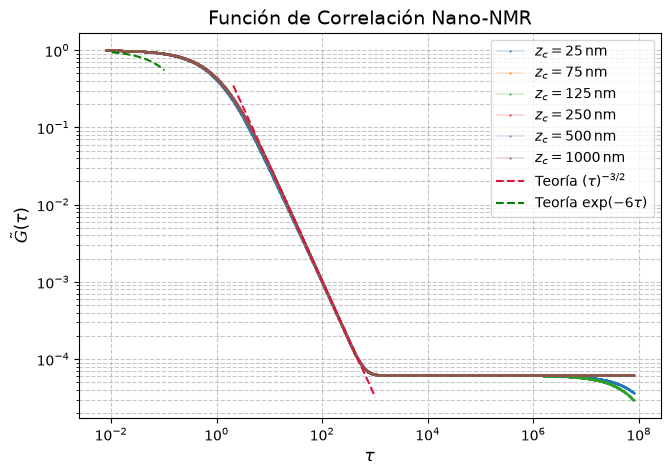

In [12]:
plt.figure(figsize=(7.5,5))
plt.loglog(tau_values1, df.G_zc25/df.G_zc25[0], "o-", label=r"$z_c=25\,\text{nm}$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values2, df.G_zc75/df.G_zc75[0], "o-", label=r"$z_c=75\,\text{nm}$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values3, df.G_zc125/df.G_zc125[0], "o-", label=r"$z_c=125\,\text{nm}$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values4, df.G_zc250/df.G_zc250[0], "o-", label=r"$z_c=250\,\text{nm}$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values5, df.G_zc500/df.G_zc500[0], "o-", label=r"$z_c=500\,\text{nm}$", markersize=0.5, linewidth=0.25)
plt.loglog(tau_values6, df.G_zc1000/df.G_zc1000[0], "o-", label=r"$z_c=1000\,\text{nm}$", markersize=0.5, linewidth=0.25)
plt.plot(tau_values1[(tau_values2>=2)&(tau_values2<=1000)], tau_values2[(tau_values2>=2)&(tau_values2<=1000)]**-1.5, "--", label=r"Teoría $(\tau)^{-3/2}$", color="crimson", linewidth=1.5)
plt.plot(tau_values1[(tau_values2>=1e-2)&(tau_values2<=0.1)], np.exp(-6*tau_values2[(tau_values2>=1e-2)&(tau_values2<=0.1)]), "--", label=r"Teoría $\exp(-6\tau)$", color="green", linewidth=1.5)
plt.xlabel("Tiempo (s)", fontsize=12)
plt.xlabel(r"$\tau$", fontsize=12)
plt.ylabel(r"$\tilde{G}(\tau)$", fontsize=12)
plt.title("Función de Correlación Nano-NMR", fontsize=14)
plt.legend()
plt.grid(which="both", ls='--', alpha=0.7)
plt.savefig("figuras/correlacion_nanoNMR_zcVariation.pdf", bbox_inches="tight", dpi=300)
plt.show()
plt.close()

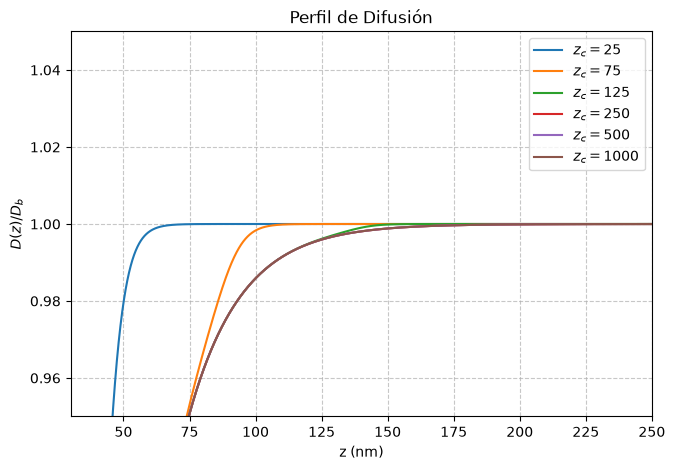

In [13]:
plt.figure(figsize=(7.5,5))
for zc in zc_list:
    D_values=D(z,zc)
    plt.plot(z, D_values/D0,label=rf"$z_c={zc}$", lw=1.5)
plt.xlabel('z (nm)')
plt.ylabel(r'$D(z)/D_b$')
plt.title('Perfil de Difusión')
plt.ylim((0.95,1.05))
plt.xlim((30,250))
plt.grid(ls='--', alpha=0.7)
plt.legend()
plt.savefig('figuras/Dz_profile_zcVariation.pdf', bbox_inches='tight')
plt.show()
plt.close()

## Conclusiones

El barrido sobre $z_c$ evidencia el papel de la extensión de la capa superficial en la señal de correlación Nano-NMR:

- Para $z_c$ pequeño ($\ll L$), la zona de baja difusividad es estrecha y $G(t)$ es poco sensible al efecto de superficie; el resultado se aproxima al caso homogéneo con $D \approx D_0$.
- Para $z_c$ grande, la zona de baja difusividad ocupa una fracción importante del cilindro, reduciendo $D_\text{eff}$ y desplazando la escala temporal característica $\tau = D_\text{eff}\, t / d^2$ hacia valores mayores.
- El cruce entre el régimen exponencial y el de ley de potencias se desplaza con $z_c$, ofreciendo un observable experimental para determinar la extensión de la capa de interfaz líquido-sólido.